In [44]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score

from sklearn.metrics import accuracy_score
import scipy.stats as stats 
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

from sklearn.metrics import r2_score
from sklearn.preprocessing import PowerTransformer
from sklearn.linear_model import LinearRegression


In [15]:
df= pd.read_csv('https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv')

In [16]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


# there is some catagorical columns we will have to apply one-Hot-encoding over those columns

In [36]:
x_encoded = pd.get_dummies(x, columns=['sex', 'smoker', 'region'],dtype=int, drop_first=True)

x_encoded.head()

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0.00001,0,1,0,0,1
1,18,33.770,1.00001,1,0,0,1,0
2,28,33.000,3.00001,1,0,0,1,0
3,33,22.705,0.00001,1,0,1,0,0
4,32,28.880,0.00001,1,0,1,0,0


In [17]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [18]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


# Here the children column contain some zero values on which box-cox will not work i have to add a very very small number to value of the children column

In [19]:
df['children'] = df['children'] + 0.00001

In [20]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094928,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000010,1121.873900
25%,27.000000,26.296250,0.000010,4740.287150
50%,39.000000,30.400000,1.000010,9382.033000
75%,51.000000,34.693750,2.000010,16639.912515
max,64.000000,53.130000,5.000010,63770.428010


In [37]:
x = df.drop(columns = ['charges'])
y = df['charges']

In [40]:
x_train , x_test , y_train , y_test = train_test_split(x_encoded,y , test_size=0.2 , random_state = 42)

In [41]:
x_train

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
560,46,19.950,2.00001,0,0,1,0,0
1285,47,24.320,0.00001,0,0,0,0,0
1142,52,24.860,0.00001,0,0,0,1,0
969,39,34.320,5.00001,0,0,0,1,0
486,54,21.470,3.00001,0,0,1,0,0
...,...,...,...,...,...,...,...,...
1095,18,31.350,4.00001,0,0,0,0,0
1130,39,23.870,5.00001,0,0,0,1,0
1294,58,25.175,0.00001,1,0,0,0,0
860,37,47.600,2.00001,0,1,0,0,1


In [45]:
# Applying Regression without any transformation
lr = LinearRegression()

lr.fit(x_train,y_train)

y_pred = lr.predict(x_test)

r2_score(y_test,y_pred)

0.7835929767120724

In [47]:
# Cross checking with cross val score
lr = LinearRegression()
np.mean(cross_val_score(lr,x_encoded,y,scoring='r2'))

np.float64(0.7468616243473741)

C:\Users\Zahoor\AppData\Local\Temp\ipykernel_19992\718371372.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train[col])


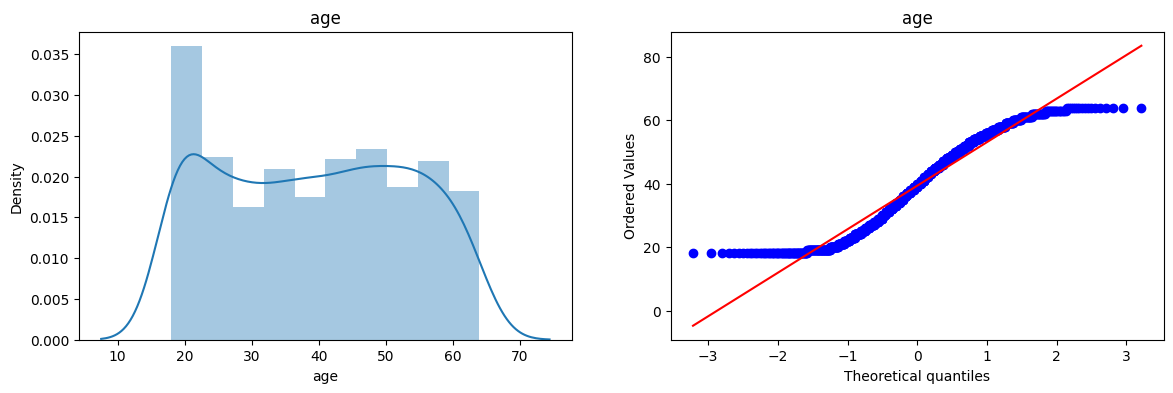

C:\Users\Zahoor\AppData\Local\Temp\ipykernel_19992\718371372.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train[col])


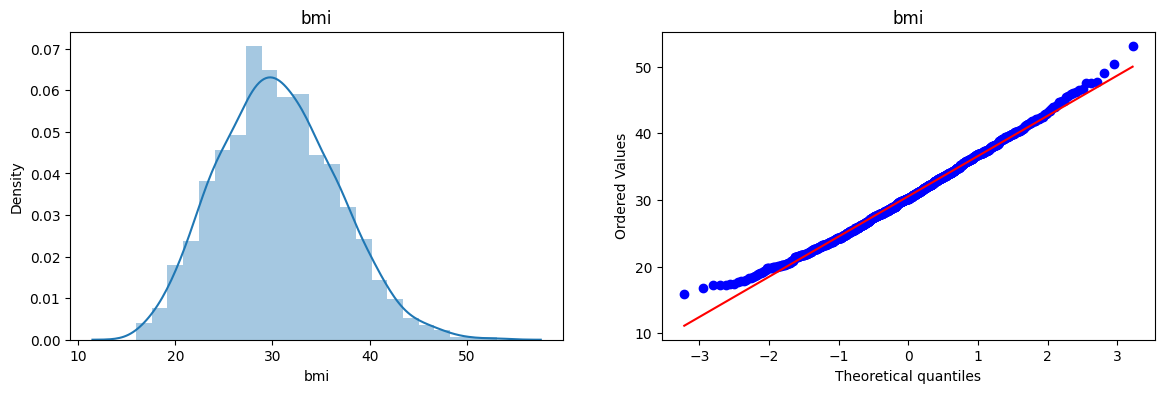

C:\Users\Zahoor\AppData\Local\Temp\ipykernel_19992\718371372.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train[col])


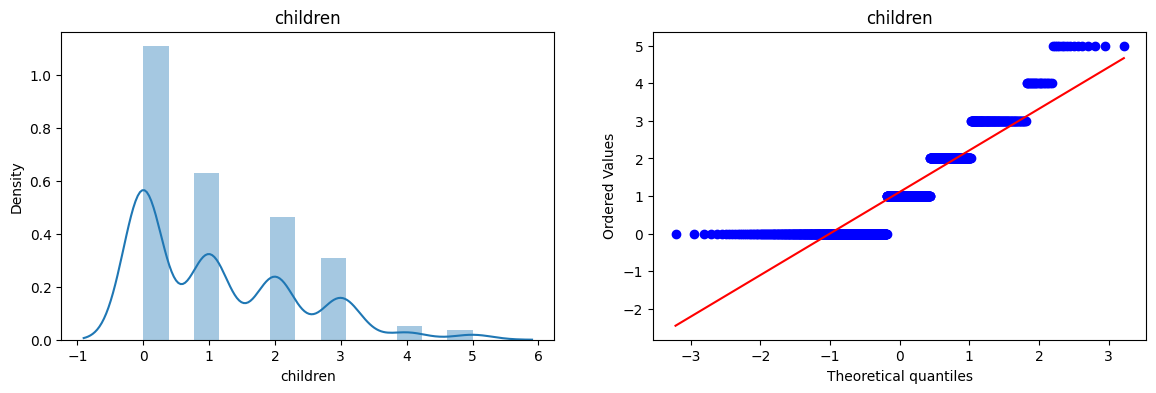

C:\Users\Zahoor\AppData\Local\Temp\ipykernel_19992\718371372.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train[col])


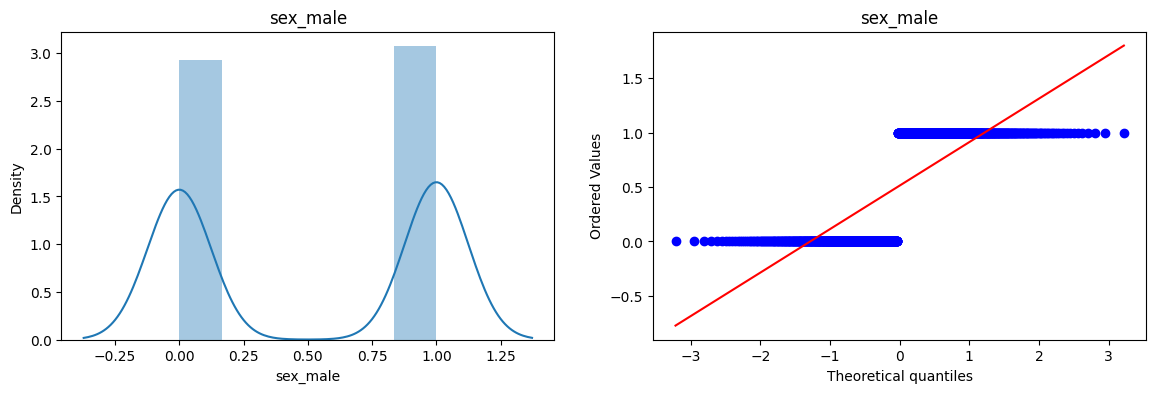

C:\Users\Zahoor\AppData\Local\Temp\ipykernel_19992\718371372.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train[col])


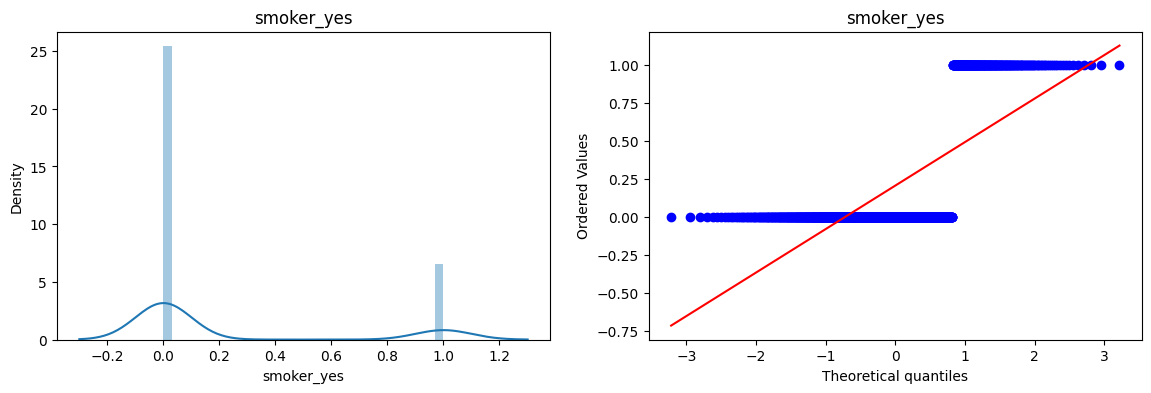

C:\Users\Zahoor\AppData\Local\Temp\ipykernel_19992\718371372.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train[col])


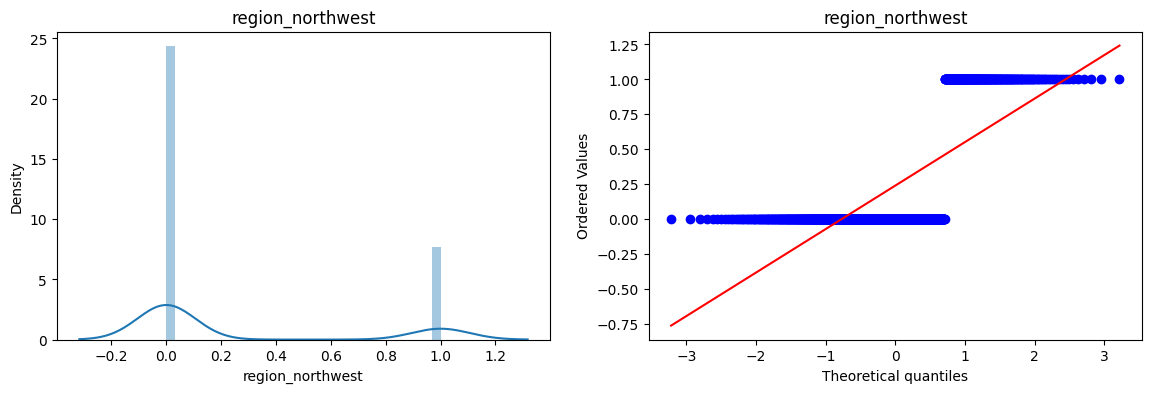

C:\Users\Zahoor\AppData\Local\Temp\ipykernel_19992\718371372.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train[col])


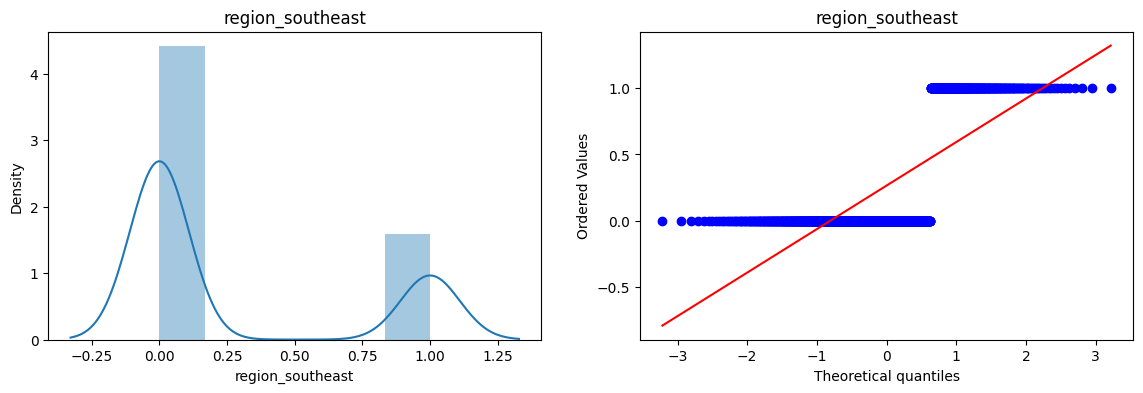

C:\Users\Zahoor\AppData\Local\Temp\ipykernel_19992\718371372.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train[col])


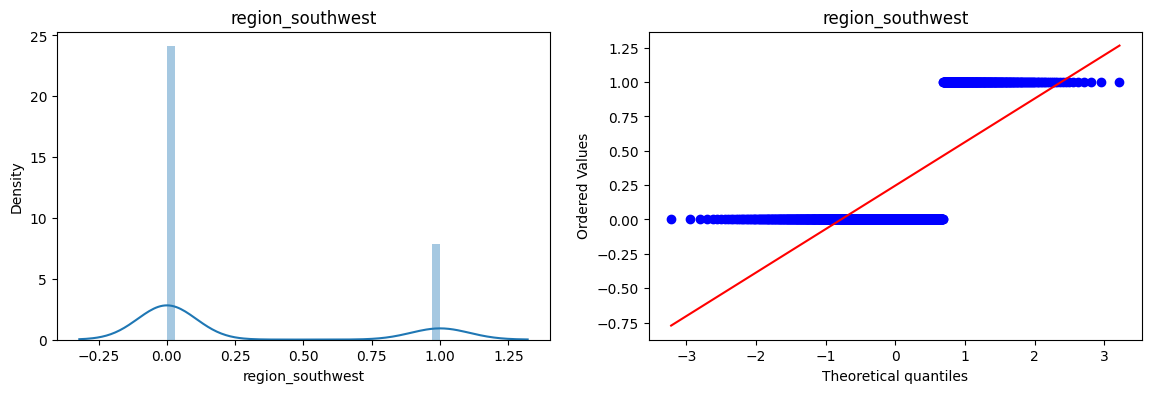

In [42]:
# Plotting the distplots without any transformation

for col in x_train.columns:
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    sns.distplot(x_train[col])
    plt.title(col)

    plt.subplot(122)
    stats.probplot(x_train[col], dist="norm", plot=plt)
    plt.title(col)

    plt.show()

# From the Distplot and QQ plot we see that the data is not normally distributed so will apply the box-cox and yeo-johnson transformation to them

In [50]:
# Applying Box-Cox Transform

pt = PowerTransformer(method='box-cox')

x_train_transformed = pt.fit_transform(x_train[['age', 'bmi', 'children']])

In [53]:
from sklearn.metrics import r2_score, mean_squared_error

In [60]:
model = LinearRegression()

model.fit(x_train, y_train)

y_pred = model.predict(x_test)

r2 = r2_score(y_test, y_pred)
print(f"R² Score: {r2:.4f}")

R² Score: 0.7836
